In [13]:
%pylab inline
import os
import gc
import glob
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
inDir='./wrkDir/database/s19-COSMOS/origin/'
outDir='./wrkDir/database/s19-COSMOS/wcut/'
hpfname='./wrkDir/database/s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits'

Populating the interactive namespace from numpy and matplotlib


In [17]:
# Add FDFC Mask
fnames=glob.glob(os.path.join(inDir,'*WIDE_DEPTH*.fits'))
for fname in fnames:
    data=pyfits.getdata(fname)
    pixmsk=utilities.get_pixel_flags(data)
    wlmsk=utilities.get_wl_flags(data)
    fdmsk=utilities.get_FDFC_flag(data,hpfname)
    bsmsk=~utilities.get_mask_briObj19I(data)
    data=data[pixmsk&wlmsk&fdmsk&bsmsk]
    print(len(data))
    outfname=os.path.join(outDir,fname.split('/')[-1])
    pyfits.writeto(outfname,data,overwrite=True)
    del data
    gc.collect()
print(fnames)

['./wrkDir/database/s19-COSMOS/origin/COSMOS_WIDE_DEPTH_WORST.fits',
 './wrkDir/database/s19-COSMOS/origin/COSMOS_WIDE_DEPTH_BEST.fits',
 './wrkDir/database/s19-COSMOS/origin/COSMOS_WIDE_DEPTH_MEDIAN.fits']

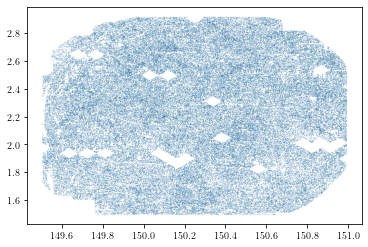

In [19]:
data=pyfits.getdata(outfname)
plt.scatter(data['i_ra'],data['i_dec'],s=0.001)

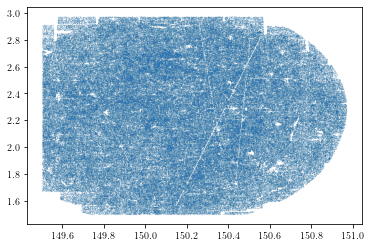

In [13]:
plt.scatter(data[~mask]['i_ra'],data[~mask]['i_dec'],s=0.001)